# Assignment 4

You will use similiar microscopic dataset - but extended version. 
>week4\all_sources_isc_vgg_embeddings.csv

Source - will include additional info both on test and cell type


## Your task
1. Diagnose dataset using PCA - checking presense of batches/techninical variables in the data.

2. Compare UMAP/tsne/pca projection
3. Validate those plots against present labels


4. Train and evaluate a KNN and SVM model - to predict label, and interpret the results

5. Perform clustering analysis using 2 distict methods and compare clustring results with present labels.

6. Try to decode label meaning

In [83]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from pathlib import Path
from umap.umap_ import UMAP


In [2]:
microscopy_home_task = pd.read_csv("all_sources_isc_vgg_embeddings.tar.gz", compression="tar")

microscopy_home_task.head()


,source,label,Value,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
0,mtt,C,94.774444,0.011359,0.241203,0.344854,0.0,11.211005,0.004637,0.0,...,0.188881,0.0,0.954637,2.482550,0.000000,0.118003,0.000000,0.000000,1.703285,0.000000
1,mtt,C,94.774444,0.025853,0.000000,1.069848,0.0,11.320415,0.000000,0.0,...,0.000000,0.0,0.168406,6.162180,0.000000,0.107752,0.000000,0.271620,4.474264,0.000000
2,mtt,C,94.774444,0.480963,0.000000,3.107252,0.0,4.831994,0.064862,0.0,...,0.124030,0.0,0.665731,1.306546,0.030879,0.144269,0.005907,0.232978,1.154307,0.000000
3,mtt,C,94.774444,0.000000,0.000000,0.058814,0.0,6.624664,0.000000,0.0,...,0.316281,0.0,0.318968,0.330109,0.480029,0.542135,0.000000,0.008872,3.581180,0.289227
4,mtt,C,94.774444,0.000000,0.000000,0.119758,0.0,8.961069,0.000000,0.0,...,0.099849,0.0,0.034700,1.626213,0.012560,0.605835,0.000000,0.025230,1.533522,0.180085


In [3]:
microscopy_home_task.isna().sum()


source         0
label          0
Value      22863
vgg_0          0
vgg_1          0
           ...  
vgg_507        0
vgg_508        0
vgg_509        0
vgg_510        0
vgg_511        0
Length: 515, dtype: int64

In [4]:
microscopy_home_task.describe()


,Value,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,vgg_7,vgg_8,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
count,982.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,...,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000,23845.000000
mean,88.145686,1.498470,0.304781,1.085484,0.355538,0.439499,0.131011,0.114659,0.667286,0.026225,...,1.339190,0.166183,1.608867,0.542775,2.118624,0.280964,0.391336,0.088719,1.003547,0.173210
std,61.962304,2.484030,0.705270,1.437526,0.591818,0.949694,0.288222,0.292859,1.165890,0.125531,...,1.733397,0.278504,2.038703,0.907855,1.650250,0.588996,0.685252,0.279512,0.648554,0.408416
min,2.454000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.575000,0.000000,0.000000,0.072552,0.000000,0.000000,0.000000,0.000000,0.005921,0.000000,...,0.307238,0.000000,0.171718,0.029046,0.930009,0.000000,0.000000,0.000000,0.557403,0.000000
50%,94.945000,0.377835,0.000000,0.539538,0.098405,0.091179,0.000811,0.000000,0.172500,0.000000,...,0.838379,0.040099,0.808060,0.189393,1.762812,0.066034,0.064119,0.000000,0.863602,0.015121
75%,120.987500,1.899906,0.273758,1.556678,0.449837,0.510618,0.131086,0.089827,0.762958,0.000000,...,1.746428,0.220630,2.259020,0.676995,2.912449,0.317651,0.496297,0.017148,1.279614,0.148648
max,271.664444,26.383339,11.761838,15.077735,8.261716,16.409120,5.181079,5.634606,12.246122,4.030687,...,18.085924,4.166559,16.153600,16.235281,18.388905,8.562617,8.496418,5.308903,8.755614,8.346353


In [17]:
target_columns = microscopy_home_task.columns.isin(['Value', 'source', 'label'])
feature_columns = microscopy_home_task.columns[~target_columns]

pca_columns = feature_columns
pca_columns


Index(['vgg_0', 'vgg_1', 'vgg_2', 'vgg_3', 'vgg_4', 'vgg_5', 'vgg_6', 'vgg_7',
       'vgg_8', 'vgg_9',
       ...
       'vgg_502', 'vgg_503', 'vgg_504', 'vgg_505', 'vgg_506', 'vgg_507',
       'vgg_508', 'vgg_509', 'vgg_510', 'vgg_511'],
      dtype='str', length=512)

In [6]:
scaler = StandardScaler()
scaler.set_output(transform='pandas')

pca_data = microscopy_home_task[pca_columns]
pca_data = pca_data - pca_data.mean(axis=0)
pca_data = pd.DataFrame(
    StandardScaler().fit_transform(pca_data),
    columns=pca_data.columns,
    index=pca_data.index,
)

pca_data.describe()


,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,vgg_7,vgg_8,vgg_9,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
count,2.384500e+04,2.384500e+04,2.384500e+04,2.384500e+04,2.384500e+04,23845.000000,2.384500e+04,2.384500e+04,2.384500e+04,2.384500e+04,...,23845.000000,2.384500e+04,23845.000000,23845.000000,2.384500e+04,2.384500e+04,2.384500e+04,2.384500e+04,2.384500e+04,2.384500e+04
mean,1.907097e-17,-1.430323e-17,2.383872e-17,-5.244518e-17,1.907097e-17,0.000000,-1.430323e-17,-2.383872e-17,-2.383872e-17,-9.535486e-18,...,0.000000,8.105164e-17,0.000000,0.000000,-1.907097e-17,-9.535486e-18,-4.767743e-18,-2.860646e-17,9.535486e-18,3.337420e-17
std,1.000021e+00,1.000021e+00,1.000021e+00,1.000021e+00,1.000021e+00,1.000021,1.000021e+00,1.000021e+00,1.000021e+00,1.000021e+00,...,1.000021,1.000021e+00,1.000021,1.000021,1.000021e+00,1.000021e+00,1.000021e+00,1.000021e+00,1.000021e+00,1.000021e+00
min,-6.032543e-01,-4.321572e-01,-7.551216e-01,-6.007684e-01,-4.627891e-01,-0.454558,-3.915251e-01,-5.723525e-01,-2.089176e-01,-4.631922e-01,...,-0.772597,-5.967118e-01,-0.789179,-0.597877,-1.283847e+00,-4.770315e-01,-5.710953e-01,-3.174150e-01,-1.547393e+00,-4.241112e-01
25%,-6.032543e-01,-4.321572e-01,-7.046504e-01,-6.007684e-01,-4.627891e-01,-0.454558,-3.915251e-01,-5.672742e-01,-2.089176e-01,-4.631922e-01,...,-0.595347,-5.967118e-01,-0.704948,-0.565883,-7.202787e-01,-4.770315e-01,-5.710953e-01,-3.174150e-01,-6.879197e-01,-4.241112e-01
50%,-4.511455e-01,-4.321572e-01,-3.797898e-01,-4.344900e-01,-3.667777e-01,-0.451744,-3.915251e-01,-4.243941e-01,-2.089176e-01,-4.631922e-01,...,-0.288925,-4.527285e-01,-0.392811,-0.389257,-2.156152e-01,-3.649170e-01,-4.775239e-01,-3.174150e-01,-2.157841e-01,-3.870874e-01
75%,1.616102e-01,-4.398831e-02,3.277883e-01,1.593400e-01,7.488799e-02,0.000259,-8.479391e-02,8.206123e-02,-2.089176e-01,-1.509686e-02,...,0.234942,1.954995e-01,0.318912,0.147846,4.810435e-01,6.228908e-02,1.531740e-01,-2.560622e-01,4.256751e-01,-6.014278e-02
max,1.001815e+01,1.624527e+01,9.733769e+00,1.335941e+01,1.681591e+01,17.521837,1.884886e+01,9.931540e+00,3.190082e+01,1.501667e+01,...,9.661428,1.436408e+01,7.134458,17.285618,9.859489e+00,1.406092e+01,1.182813e+01,1.867646e+01,1.195310e+01,2.001221e+01


In [7]:
pca = PCA(n_components=50, random_state=42)
pcs = pca.fit_transform(pca_data)

pca_df = pd.DataFrame(pcs[:, :10],
                      columns=[f"PC{i+1}" for i in range(10)],
                      index=pca_data.index)
pca_df = pca_df.join(microscopy_home_task[["source", "label", "Value"]])
pca_df.head()


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,source,label,Value
0,0.051980,8.332027,-17.795325,-7.854225,7.051670,-4.584386,1.253499,6.806754,-7.107531,-2.424292,mtt,C,94.774444
1,-0.089908,13.613370,-20.364673,-11.102960,11.692853,-6.335967,0.500361,9.030953,-6.715713,-3.614192,mtt,C,94.774444
2,1.462632,9.766665,-17.441183,-8.631860,7.919277,-5.288184,1.278977,6.180611,-6.338099,-4.186965,mtt,C,94.774444
3,0.667550,11.097592,-17.874090,-9.676703,9.608685,-8.045801,1.022522,8.757884,-7.557388,0.359786,mtt,C,94.774444
4,1.261371,13.357259,-19.615117,-8.523626,10.751495,-8.055660,0.933598,11.331835,-10.003658,-3.562722,mtt,C,94.774444


/tmp/ipykernel_2787/3505895816.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


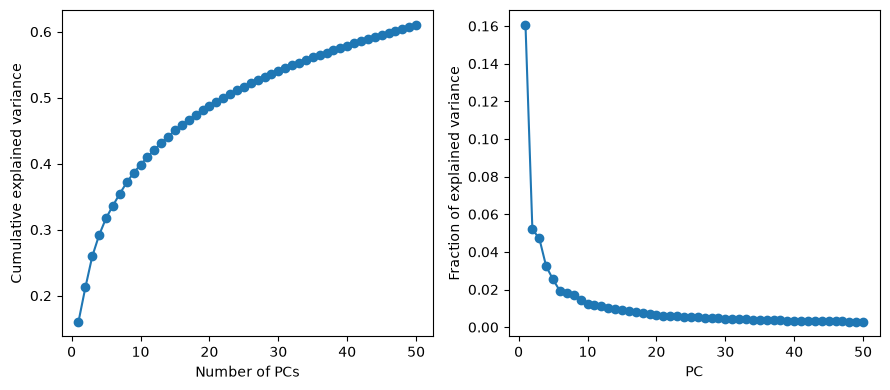

In [8]:
evr = pca.explained_variance_ratio_
fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(9, 4))

ax[0].plot(range(1, len(evr) + 1), evr.cumsum(), marker="o")
ax[0].set_xlabel("Number of PCs")
ax[0].set_ylabel("Cumulative explained variance")

ax[1].plot(range(1, len(evr) + 1), evr, marker="o")
ax[1].set_xlabel("PC")
ax[1].set_ylabel("Fraction of explained variance")

fig.tight_layout()
fig.show()


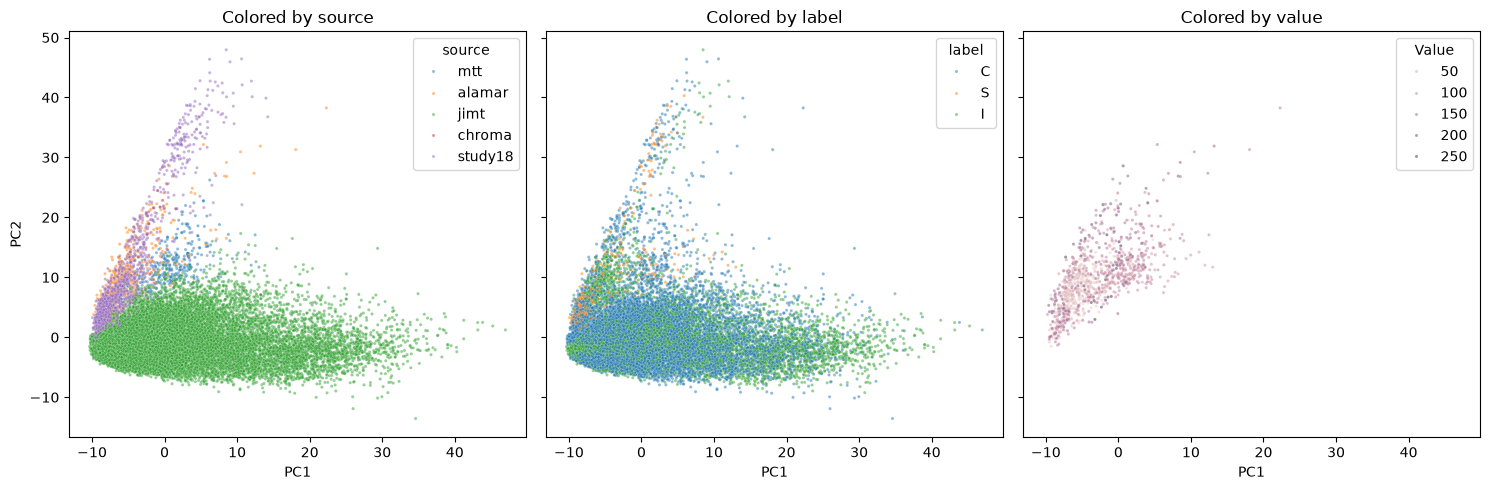

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="source", s=5, alpha=0.5, ax=axes[0])
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label",  s=5, alpha=0.5, ax=axes[1])
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Value",  s=5, alpha=0.5, ax=axes[2])
axes[0].set_title("Colored by source")
axes[1].set_title("Colored by label")
axes[2].set_title("Colored by value")
fig.tight_layout()
plt.show()


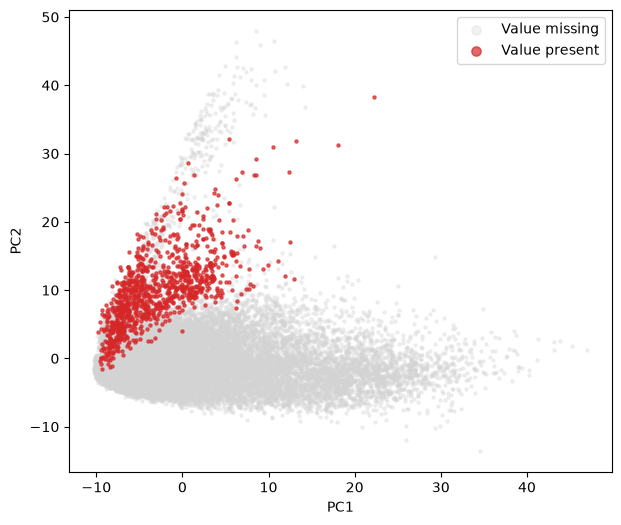

In [10]:
missing = pca_df["Value"].isna()

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(pca_df.loc[missing, "PC1"],  pca_df.loc[missing, "PC2"],
           s=5, alpha=0.3, c="lightgrey", label="Value missing")
ax.scatter(pca_df.loc[~missing, "PC1"], pca_df.loc[~missing, "PC2"],
           s=5, alpha=0.7, c="tab:red",   label="Value present")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(markerscale=3)
plt.show()


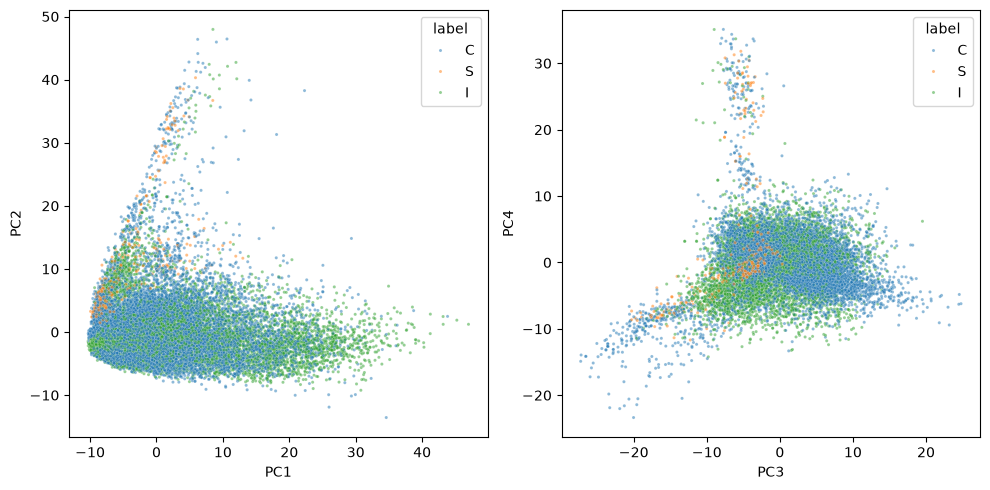

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label", s=5, alpha=0.5, ax=axes[0])
sns.scatterplot(data=pca_df, x="PC3", y="PC4", hue="label",  s=5, alpha=0.5, ax=axes[1])
fig.tight_layout()
plt.show()


There is a clear batch effect from source. At the same time, labels don't seem to differentiate the data meaningfully.

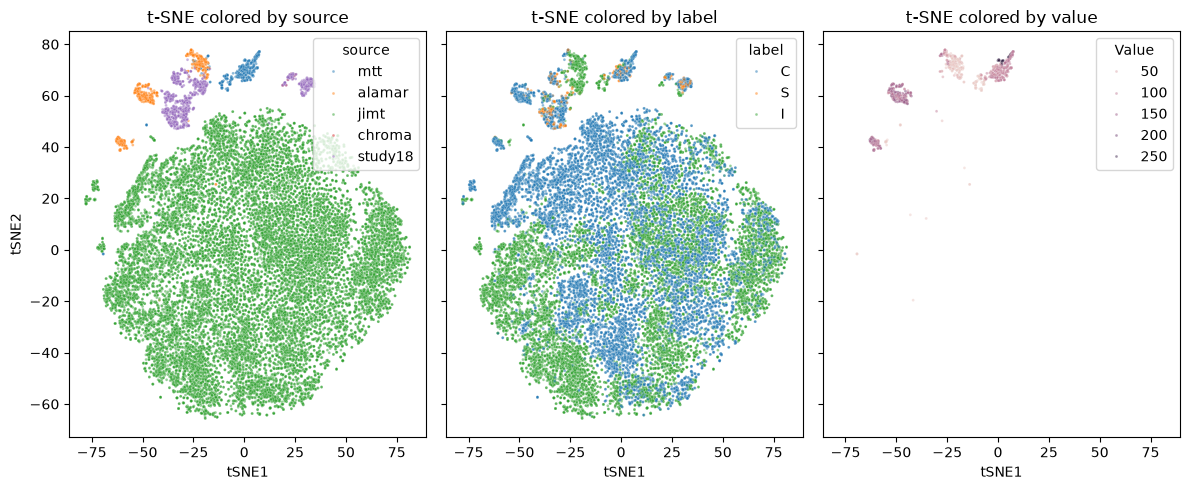

In [ ]:
tsne = TSNE(
  n_components=2,
  perplexity=30,
  init="pca",
  learning_rate="auto",
  max_iter=750,
  random_state=42,
)

x_tsne = tsne.fit_transform(pcs)

tsne_df = pd.DataFrame(x_tsne, columns=["tSNE1", "tSNE2"], index=pca_data.index)
tsne_df = tsne_df.join(microscopy_home_task[["source", "label", "Value"]])

fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharex=True, sharey=True)
sns.scatterplot(data=tsne_df, x="tSNE1", y="tSNE2", hue="source", s=4, alpha=0.5, ax=axes[0])
sns.scatterplot(data=tsne_df, x="tSNE1", y="tSNE2", hue="label",  s=4, alpha=0.5, ax=axes[1])
sns.scatterplot(data=tsne_df, x="tSNE1", y="tSNE2", hue="Value",  s=4, alpha=0.5, ax=axes[2])
axes[0].set_title("t-SNE colored by source")
axes[1].set_title("t-SNE colored by label")
axes[2].set_title("t-SNE colored by value")
fig.tight_layout()
plt.show()


In [ ]:
umap = UMAP(
  n_neighbors=15,
  min_dist=0.1,
  random_state=42,
  n_jobs=-1
)

x_umap = umap.fit_transform(pcs)

umap_df = pd.DataFrame(x_umap, columns=["UMAP1", "UMAP2"], index=pca_data.index)
umap_df = umap_df.join(microscopy_home_task[["source", "label", "Value"]])


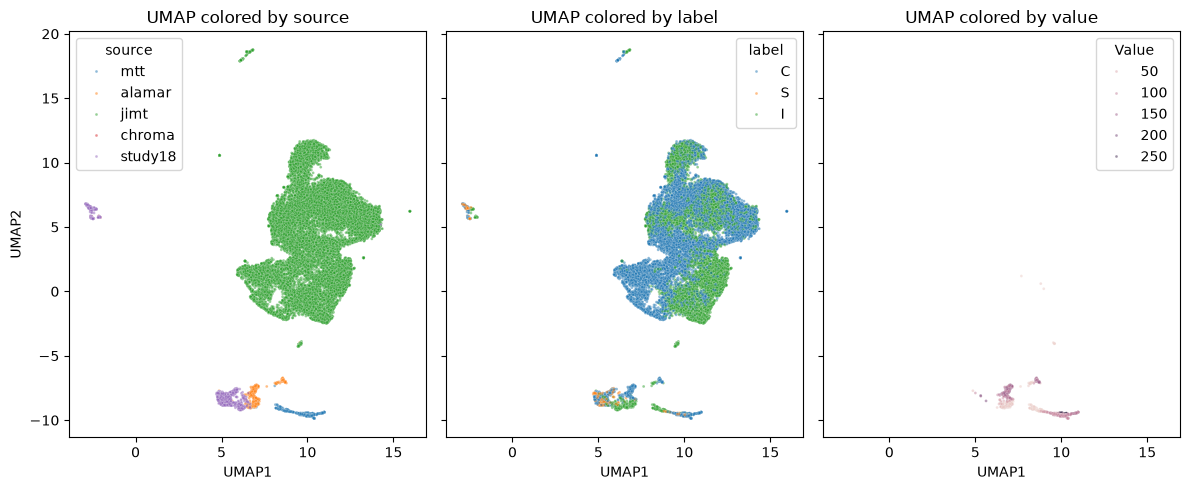

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharex=True, sharey=True)
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="source", s=4, alpha=0.5, ax=axes[0])
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="label",  s=4, alpha=0.5, ax=axes[1])
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Value",  s=4, alpha=0.5, ax=axes[2])
axes[0].set_title("UMAP colored by source")
axes[1].set_title("UMAP colored by label")
axes[2].set_title("UMAP colored by value")
fig.tight_layout()
plt.show()


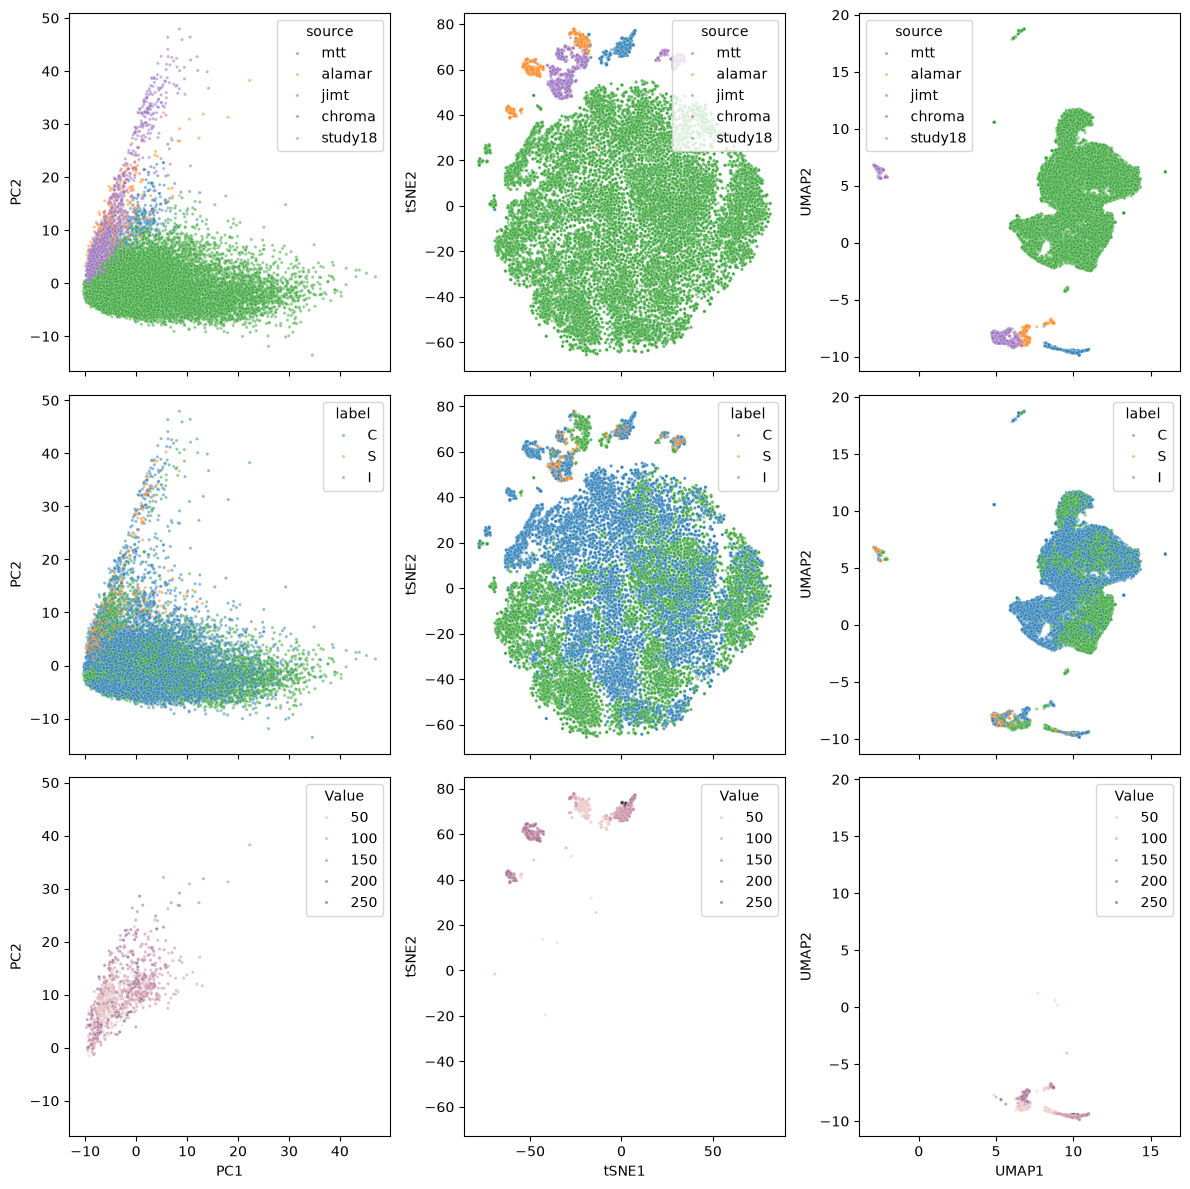

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12), sharex="col", sharey="col")

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="source", s=5, alpha=0.5, ax=axes[0][0])
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label",  s=5, alpha=0.5, ax=axes[1][0])
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Value",  s=5, alpha=0.5, ax=axes[2][0])

sns.scatterplot(data=tsne_df, x="tSNE1", y="tSNE2", hue="source", s=5, alpha=0.5, ax=axes[0][1])
sns.scatterplot(data=tsne_df, x="tSNE1", y="tSNE2", hue="label",  s=5, alpha=0.5, ax=axes[1][1])
sns.scatterplot(data=tsne_df, x="tSNE1", y="tSNE2", hue="Value",  s=5, alpha=0.5, ax=axes[2][1])

sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="source", s=5, alpha=0.5, ax=axes[0][2])
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="label",  s=5, alpha=0.5, ax=axes[1][2])
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Value",  s=5, alpha=0.5, ax=axes[2][2])
fig.tight_layout()
plt.show()


We can see clear separation between sources in all three techniques. But separation between labels is much clearer in t-SNE and UMAP than in PCA. Also, similar "Value" samples seem to cluster together in those techniques (especially in t-SNE).

## Classification

In [19]:
X = microscopy_home_task[feature_columns]
X


,vgg_0,vgg_1,vgg_2,vgg_3,vgg_4,vgg_5,vgg_6,vgg_7,vgg_8,vgg_9,...,vgg_502,vgg_503,vgg_504,vgg_505,vgg_506,vgg_507,vgg_508,vgg_509,vgg_510,vgg_511
0,0.011359,0.241203,0.344854,0.000000,11.211005,0.004637,0.0,4.324963,0.186122,0.634246,...,0.188881,0.0,0.954637,2.482550,0.000000,0.118003,0.000000,0.000000,1.703285,0.000000
1,0.025853,0.000000,1.069848,0.000000,11.320415,0.000000,0.0,4.964942,0.000000,0.000000,...,0.000000,0.0,0.168406,6.162180,0.000000,0.107752,0.000000,0.271620,4.474264,0.000000
2,0.480963,0.000000,3.107252,0.000000,4.831994,0.064862,0.0,1.545585,0.000000,0.600580,...,0.124030,0.0,0.665731,1.306546,0.030879,0.144269,0.005907,0.232978,1.154307,0.000000
3,0.000000,0.000000,0.058814,0.000000,6.624664,0.000000,0.0,2.789257,0.035929,0.048643,...,0.316281,0.0,0.318968,0.330109,0.480029,0.542135,0.000000,0.008872,3.581180,0.289227
4,0.000000,0.000000,0.119758,0.000000,8.961069,0.000000,0.0,1.365339,0.053993,0.128564,...,0.099849,0.0,0.034700,1.626213,0.012560,0.605835,0.000000,0.025230,1.533522,0.180085
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23840,0.059749,0.000000,0.000000,0.312913,0.053099,0.000000,0.0,0.025735,0.000000,0.000000,...,0.198128,0.0,0.024524,0.771849,0.000000,0.002295,0.000000,0.000000,0.800087,0.000000
23841,0.000000,0.000000,1.000184,0.000000,0.740112,0.000000,0.0,0.000000,0.000000,0.000000,...,0.434452,0.0,0.000000,0.732429,0.000000,0.662563,0.000000,0.000000,0.678243,0.000000
23842,0.000000,0.000000,0.677755,0.000000,2.872867,0.000000,0.0,0.000000,0.000000,0.000000,...,2.191196,0.0,0.023503,0.882949,0.000000,0.059748,0.000000,0.000000,0.889415,0.000000
23843,0.000000,0.000000,0.020610,0.000000,2.368106,0.035866,0.0,0.081344,0.000000,0.000000,...,0.834328,0.0,0.051658,0.039791,4.803977,0.000000,0.000000,0.000000,1.185690,0.000000


In [20]:
y = microscopy_home_task['label']
y


0        C
1        C
2        C
3        C
4        C
        ..
23840    S
23841    S
23842    S
23843    S
23844    S
Name: label, Length: 23845, dtype: str

label
I    11978
C    11591
S      276
Name: count, dtype: int64

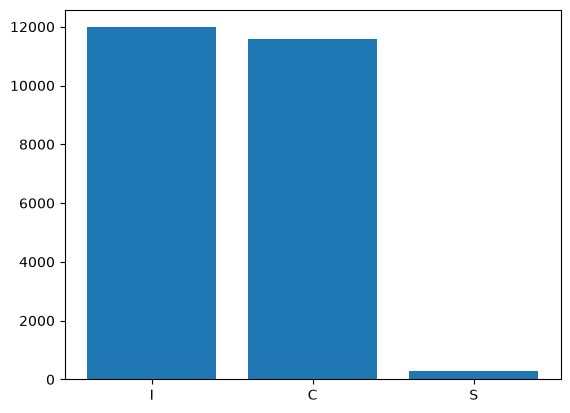

In [28]:
counts = y.value_counts()

display(counts)
plt.bar(counts.index, counts)
plt.show()


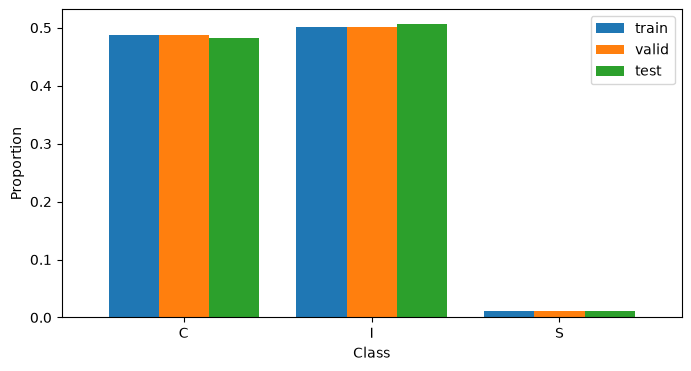

In [ ]:
x_train_valid, x_test, y_train_valid, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
x_train, x_valid, y_train, y_valid = train_test_split(x_train_valid, y_train_valid, test_size=0.25, random_state=42)

y_train_counts = y_train.value_counts()
y_valid_counts = y_valid.value_counts()
y_test_counts = y_test.value_counts()

dist = pd.DataFrame({
  'train': y_train.value_counts(normalize=True),
  'valid': y_valid.value_counts(normalize=True),
  'test':  y_test.value_counts(normalize=True),
}).sort_index()

dist.plot.bar(figsize=(8, 4), width=0.8)
plt.ylabel('Proportion')
plt.xlabel('Class')
plt.xticks(rotation=0)
plt.show()


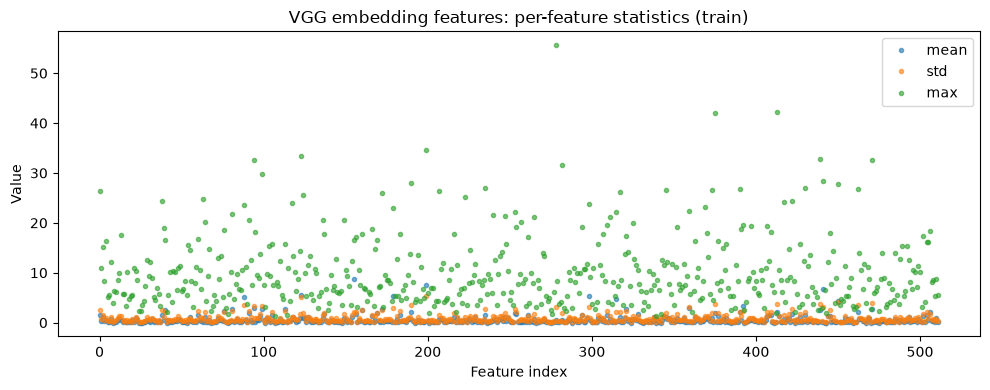

In [36]:
stats = x_train.describe().T  # one row per feature

plt.figure(figsize=(10, 4))
plt.plot(stats["mean"].to_numpy(), ".", label="mean", alpha=0.6)
plt.plot(stats["std"].to_numpy(), ".", label="std", alpha=0.6)
plt.plot(stats["max"].to_numpy(), ".", label="max", alpha=0.6)
plt.xlabel("Feature index")
plt.ylabel("Value")
plt.title("VGG embedding features: per-feature statistics (train)")
plt.legend()
plt.tight_layout()
plt.show()


In [40]:
def classifier_metrics(y_pred, y_eval):
  return {
    "accuracy": accuracy_score(y_eval, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_eval, y_pred),
    "macro_f1": f1_score(y_eval, y_pred, average="macro"),
  }

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)

y_pred = knn.predict(x_valid)

knn_metrics = classifier_metrics(y_pred, y_valid)
display(pd.Series(knn_metrics, name="KNN").to_frame())


,KNN
accuracy,0.918222
balanced_accuracy,0.749070
macro_f1,0.777192


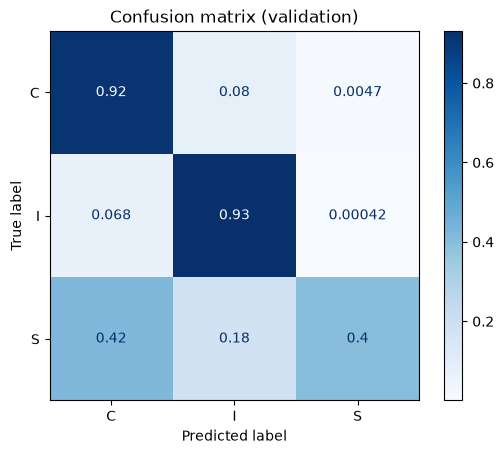

In [49]:
ConfusionMatrixDisplay.from_estimator(knn, x_valid, y_valid, cmap="Blues", normalize='true')
plt.title("Confusion matrix (validation)")
plt.show()


Best k: 4


,k,accuracy,balanced_accuracy,macro_f1
0,1,0.933948,0.772720,0.763601
1,2,0.914447,0.688314,0.717348
2,3,0.929126,0.769460,0.776874
3,4,0.916544,0.754879,0.782108
4,5,0.918222,0.749070,0.777192
5,6,0.911512,0.718719,0.750667
6,7,0.911092,0.750777,0.772693
7,8,0.903124,0.699970,0.730956
8,9,0.904592,0.700723,0.731873
9,10,0.897043,0.689320,0.726166


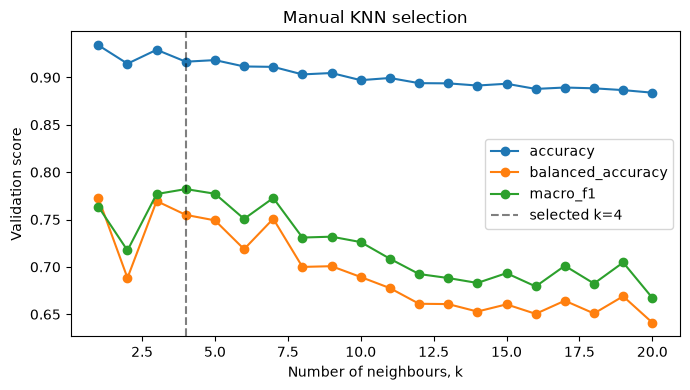

In [51]:
ns = range(1, 21)

knn_results = []
for n in ns:
  knn = KNeighborsClassifier(n_neighbors=n, n_jobs=4)
  knn.fit(x_train, y_train)
  y_pred = knn.predict(x_valid)
  metrics = classifier_metrics(y_pred, y_valid)
  knn_results.append({ "k": n, **metrics })

knn_results = pd.DataFrame(knn_results)

best_k = int(knn_results.loc[knn_results["macro_f1"].idxmax(), "k"])
print(f"Best k: {best_k}")

display(knn_results)

plt.figure(figsize=(7, 4))
for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
    plt.plot(knn_results["k"], knn_results[metric], marker="o", label=metric)
plt.axvline(best_k, color="black", linestyle="--", alpha=0.5, label=f"selected k={best_k}")
plt.xlabel("Number of neighbours, k")
plt.ylabel("Validation score")
plt.title("Manual KNN selection")
plt.legend()
plt.tight_layout()
plt.show()



In [52]:
svm_linear = SVC(kernel="linear", C=0.01)
svm_linear.fit(x_train, y_train)
y_pred = svm_linear.predict(x_valid)
svm_linear_metrics = classifier_metrics(y_pred, y_valid)
display(pd.Series(svm_linear_metrics, name="linear SVM").to_frame())


,linear SVM
accuracy,0.846718
balanced_accuracy,0.622666
macro_f1,0.651738


In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
  svm_linear,
  {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": [0.01, 0.5, 1, 1.5, 2],
  },
  cv=cv,
  scoring="f1_macro",
  n_jobs=-1,
  refit=True,
  random_state=42,
  n_iter=1000,
)

search.fit(x_train, y_train)
print(search.best_params_)
print(f"Best macro F1: {search.best_score_}")


/home/alegator1209/kse/ml/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/model_selection/_search.py:326: UserWarning: The total space of parameters 20 is smaller than n_iter=1000. Running 20 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


{'kernel': 'rbf', 'C': 2}
Best macro F1: 0.7235848937265297


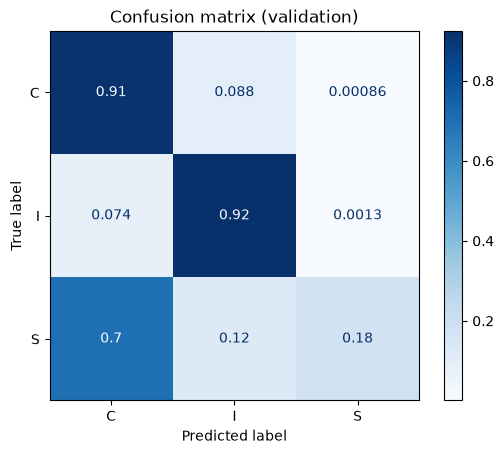

In [61]:
svm = search.best_estimator_

ConfusionMatrixDisplay.from_estimator(svm, x_valid, y_valid, cmap="Blues", normalize='true')
plt.title("Confusion matrix (validation)")
plt.show()


KNN seem to fit better for the task. While both models differentiate well between the two main classes - C and I, SVN almost always (82% of cases) misclassifies S, compared to KNN (60%). Class S is under-represented and, from dimensionality reduction, is hard to distinguish from class C. That's why we see so much S->C missclassifications in both models.

Hyperparameter search helped to significantly improve SVN macro F1 score (0.65 -> 0.72), but it still lags behind KNN (0.78).

XGBoost is recommended as the next step to improve performance.

## Clustering

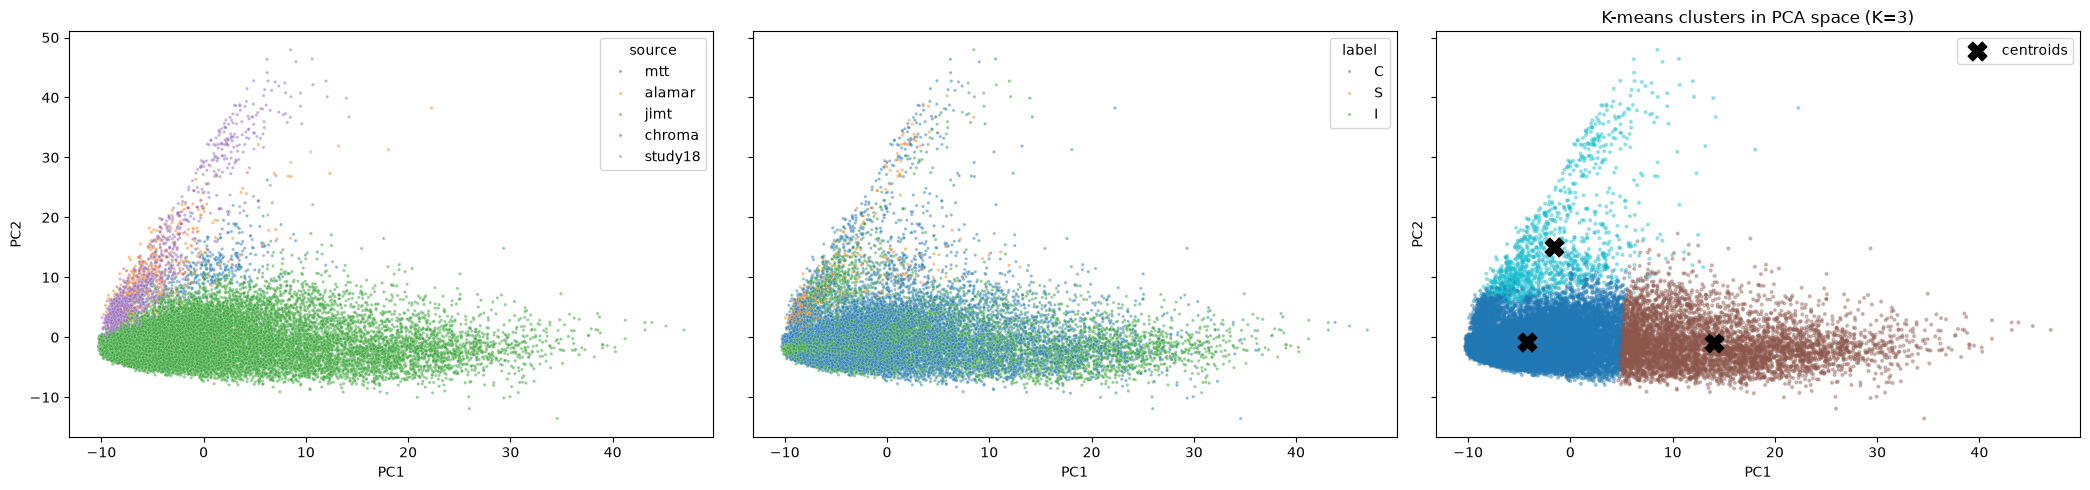

In [89]:
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(pcs)

fig, ax = plt.subplots(ncols=3, figsize=(21, 5), sharex=True, sharey=True)

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="source",  s=5, alpha=0.5, ax=ax[0])
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label",  s=5, alpha=0.5, ax=ax[1])
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")

ax[2].scatter(pcs[:, 0], pcs[:, 1], c=cluster_labels, cmap="tab10", s=4, alpha=0.35)
ax[2].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="X", s=180, c="black", label="centroids")
ax[2].set_xlabel("PC1")
ax[2].set_ylabel("PC2")
ax[2].set_title(f"K-means clusters in PCA space (K={n_clusters})")
ax[2].legend()

fig.tight_layout()
plt.show()


In [74]:
k_values = range(2, 9)
inertias = []
silhouettes = []
for k in k_values:
  candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
  labels = candidate.fit_predict(pcs)
  inertias.append(candidate.inertia_)
  silhouettes.append(silhouette_score(pcs, labels, sample_size=min(5000, len(pcs)), random_state=42))

cluster_diagnostics = pd.DataFrame({"K": list(k_values), "inertia": inertias, "silhouette": silhouettes})
display(cluster_diagnostics)
selected_k = int(cluster_diagnostics.loc[cluster_diagnostics["silhouette"].idxmax(), "K"])
print("Selected K from the largest silhouette score:", selected_k)


,K,inertia,silhouette
0,2,6.076797e+06,0.325739
1,3,5.609819e+06,0.331594
2,4,5.211618e+06,0.202888
3,5,4.907217e+06,0.210571
4,6,4.667918e+06,0.177204
5,7,4.509420e+06,0.106779
6,8,4.357706e+06,0.111575


Selected K from the largest silhouette score: 3


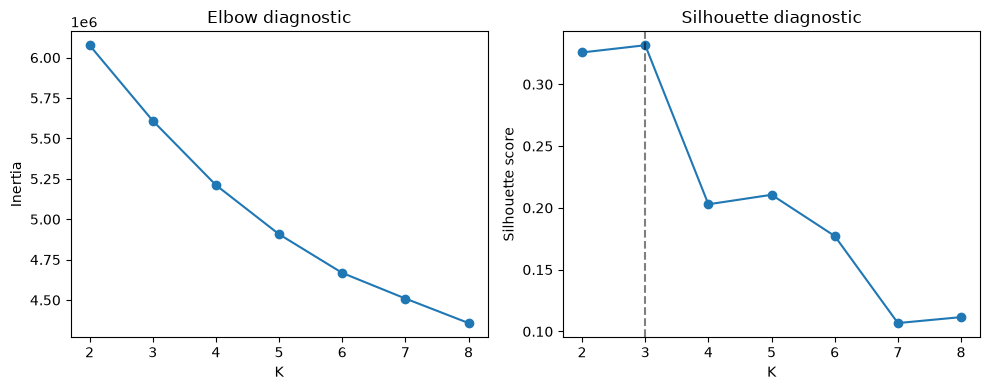

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(cluster_diagnostics["K"], cluster_diagnostics["inertia"], marker="o")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow diagnostic")
axes[1].plot(cluster_diagnostics["K"], cluster_diagnostics["silhouette"], marker="o")
axes[1].axvline(selected_k, color="black", linestyle="--", alpha=0.5)
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette diagnostic")
plt.tight_layout()
plt.show()


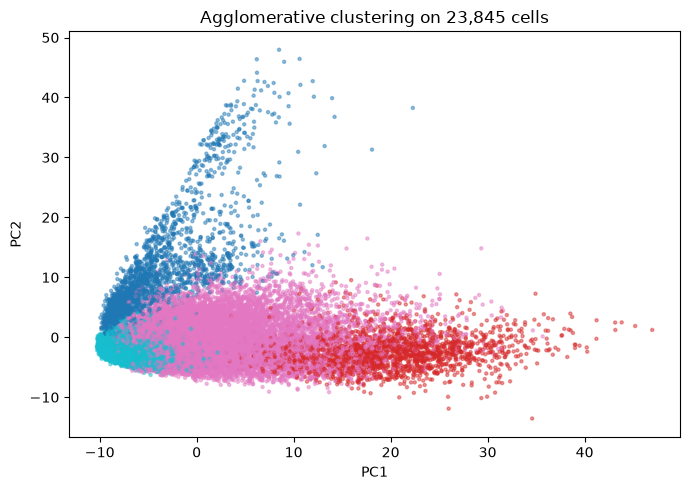

In [82]:
hierarchical_size = len(pcs)
hierarchical_indices = np.random.default_rng(42).choice(len(pcs), size=hierarchical_size, replace=False)
hierarchical_model = AgglomerativeClustering(n_clusters=4, linkage="ward")
hierarchical_labels = hierarchical_model.fit_predict(pcs[hierarchical_indices])

plt.figure(figsize=(7, 5))
plt.scatter(pcs[hierarchical_indices, 0], pcs[hierarchical_indices, 1], c=hierarchical_labels, cmap="tab10", s=5, alpha=0.45)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Agglomerative clustering on {hierarchical_size:,} cells")
plt.tight_layout()
plt.show()


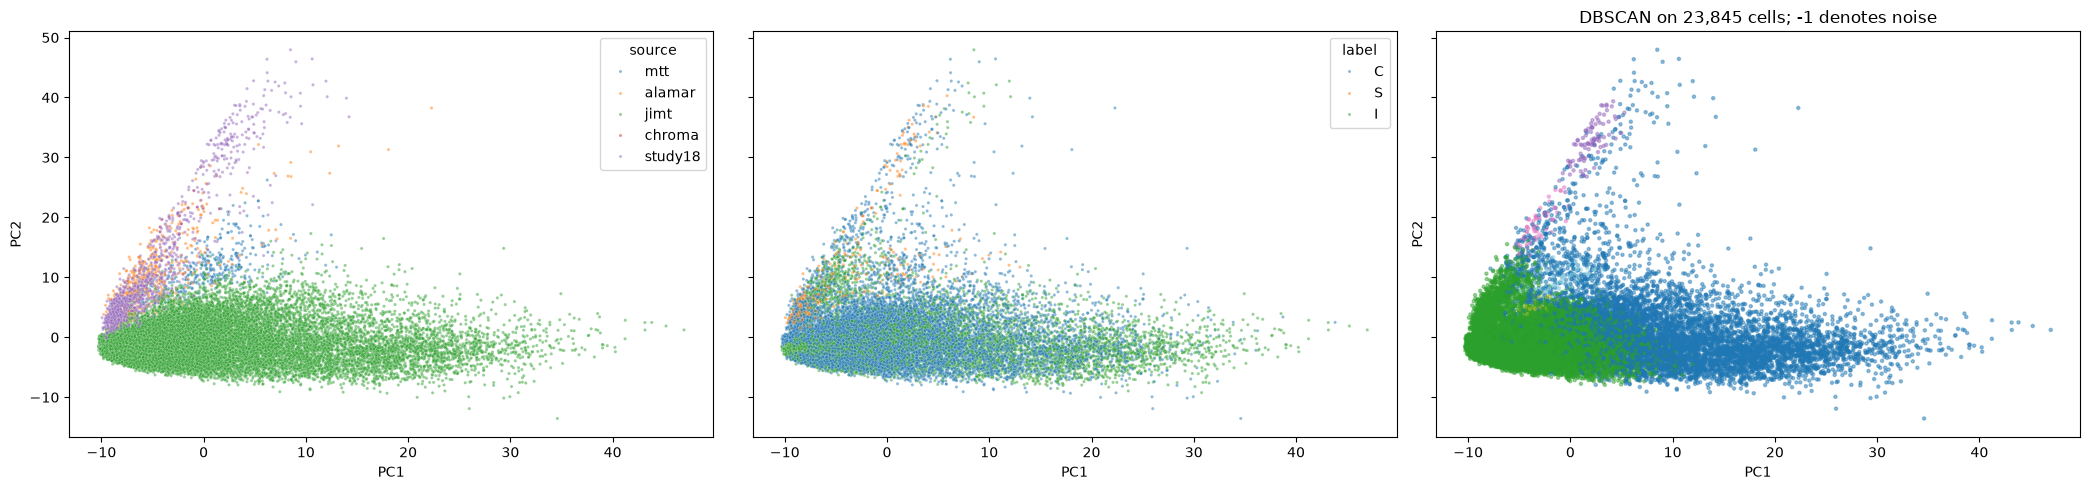

DBSCAN noise fraction: 0.306


In [90]:
dbscan_size = len(pcs)
dbscan_indices = np.random.default_rng(42 + 1).choice(len(pcs), size=dbscan_size, replace=False)
dbscan = DBSCAN(eps=10.0, min_samples=15, n_jobs=-1)
dbscan_labels = dbscan.fit_predict(pcs[dbscan_indices])

fig, ax = plt.subplots(ncols=3, figsize=(21, 5), sharex=True, sharey=True)

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="source",  s=5, alpha=0.5, ax=ax[0])
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")


sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label",  s=5, alpha=0.5, ax=ax[1])
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")

ax[2].scatter(pcs[dbscan_indices, 0], pcs[dbscan_indices, 1], c=dbscan_labels, cmap="tab20", s=5, alpha=0.45)
ax[2].set_xlabel("PC1")
ax[2].set_ylabel("PC2")
ax[2].set_title(f"DBSCAN on {dbscan_size:,} cells; -1 denotes noise")

fig.tight_layout()
plt.show()
print("DBSCAN noise fraction:", round(float((dbscan_labels == -1).mean()), 3))


K-means and agglomerative clustering produced similar clusters that align well with source, but not so well by label. All algorithms detected separate clusters in the top-left part of the plot, that correspond to other sources than jimt, that dominates the dataset. Only DBSCAN revealed some more complex structure in that region, defining several separate clusters.

Anyway, clustering doesn't seem to align well with labels. The border between sources is clear in KNN and agglomerative clutering, but DBSCAN missed it.

# Label analysis

/tmp/ipykernel_2787/990352490.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


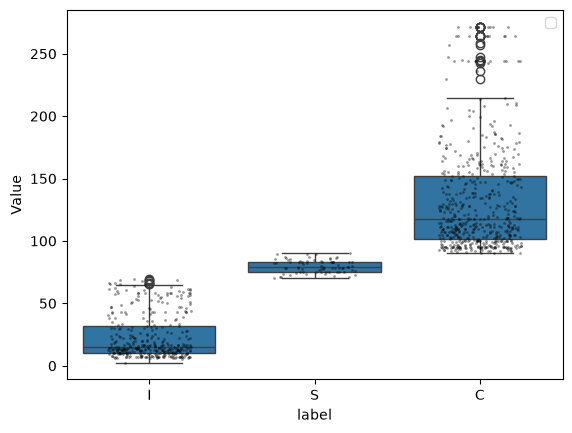

In [102]:
df = microscopy_home_task[["label", "Value"]].dropna()
order = ["I", "S", "C"]

ax = sns.boxplot(data=df, x="label", y="Value", order=order)
sns.stripplot(data=df, x="label", y="Value", order=order, color="black", size=2, alpha=0.4, jitter=0.25, ax=ax)
ax.set_ylabel("Value")
ax.legend()
plt.show()


There seem to be a clear dependency between values and labels. It also seems that each lebel is defined by some thresholds.

Source names hint on cell viability assays (Alamar Blue used to asses cell death, jimt is a cell line used to observe live cells and study toxicity).

My guess then is that labels are broad categories of cell survivability or treatments. C probably stands for "control", I may stand for "inhibited" and "s" for "stable". Another hint is the range of the "value". 100 probably means population size is 100% of initial, lower than ~75% we have inhibited population, and up than 100% - normal, growing population. S population then maintains its size but doesn't grow.